In [3]:

#Standard libraries
import time

#Numerical computation and plotting
import numpy as np
import matplotlib.pyplot as plt

#SciPy special functions for Slepian basis functions
from scipy.special import pro_ang1


In [4]:
#Experiment parameters
#Training sample sizes: 10 values from 100 to 10,000, on a log scale
sample_sizes = np.logspace(2, 4, 10).astype(int)

# Test-set size: 20% of the training-set size
test_fraction = 0.2
#Ntest = 1000

# Slepian basis sizes: 1, 4, 8, ..., 36
max_order_slep = 35
n_basis_values = np.linspace(
    1, max_order_slep + 1, 10
).astype(int)

# Number of independent repetitions
n_runs = 20


In [5]:
#Generate random sample points uniformly on [-1, 1]
rng = np.random.default_rng(42)

def generate_samples(n_samples):
    """Generate independent uniform samples on [-1, 1]."""
    return rng.uniform(-1, 1, size=int(n_samples))


In [7]:

# Calculate the normalization quantity for a Slepian function

def slepian_normalization(degree, bandwidth):
    alpha = 0
    theta = np.linspace(-1, 1, 200)

    pswf_values = pro_ang1(alpha, degree, bandwidth, theta)
    pswf_values = pswf_values[0]

    pswf_values = pswf_values[1:199]

    normalization = np.sqrt(
        0.5 * np.trapezoid(
            np.abs(pswf_values)**2,
            x=theta[1:-1]
        )
    )

    return normalization


slepian_norms = np.zeros(n_basis_values[-1])

for degree in range(n_basis_values[-1]):
    slepian_norms[degree] = slepian_normalization(degree, 16)


In [2]:

#Evaluate the normalized Slepian function of degree j and bandwidth c

def normalized_slepian(x, degree, bandwidth):
    alpha = 0

    pswf_values = pro_ang1(alpha, degree, bandwidth, x)
    pswf_values = pswf_values[0]

    normalization = slepian_norms[degree]

    return pswf_values / normalization



In [14]:
# Build the matrix for the least-squares approximation using normalized Slepian functions

def build_slepian_matrix(samples, n_basis):
    A = np.zeros((len(samples), n_basis))

    for j in range(n_basis):
        A[:, j] = normalized_slepian(samples, j, 16)

    return A

In [15]:
#This is the function that we approximate
def funct(x):
    g = np.cos(10*x) * np.exp(-np.pi*x**2)
    return g



In [17]:

# Run the least-squares experiments

# Store test RMSE for each basis size, sample size, and run
MSE = np.zeros((len(n_basis_values), len(sample_sizes), n_runs))

start_time = time.time()
total_iterations = n_runs * len(n_basis_values) * len(sample_sizes)
counter = 0

for run in range(n_runs):
    # Generate the largest training set once, then use subsets
    SamSet_ = generate_samples(sample_sizes[-1])
    y_ = funct(SamSet_)
    A_ = build_slepian_matrix(SamSet_, n_basis_values[-1])

    for k in range(len(sample_sizes)):
        # Select the required number of training samples
        A = A_[:sample_sizes[k], :]
        y = y_[:sample_sizes[k]]

        # Generate one independent test set for this sample size
        n_test = int(test_fraction * sample_sizes[k])
        TestSet = generate_samples(n_test)
        Values_test = funct(TestSet)

        # Build the largest test matrix once; smaller bases use its first columns
        test_PSWF_matrix = build_slepian_matrix(
            TestSet, n_basis_values[-1]
        )

        for orde in range(len(n_basis_values)):
            # Select the required number of basis functions
            A_current = A[:, :n_basis_values[orde]]
            test_matrix = test_PSWF_matrix[:, :n_basis_values[orde]]

            # Solve the least-squares problem directly
            x, _, _, _ = np.linalg.lstsq(
                A_current, y, rcond=None
            )

            # Evaluate the approximation on the test set
            linear_combination_t = test_matrix @ x

            # Calculate the test RMSE
            Err = np.linalg.norm(
                linear_combination_t - Values_test
            ) / np.sqrt(n_test)

            MSE[orde, k, run] = Err

            counter += 1
            now_time = time.time()
            remaining_time = (
                (total_iterations - counter)
                * (now_time - start_time)
                / counter
            )

            print(
                f"Error: {Err:.6e}, "
                f"Progress: {100 * counter / total_iterations:.2f}%, "
                f"approx. {remaining_time:.1f} seconds remaining."
            )


Error: 3.117772e-01, Progress: 0.05%, approx. 104913.1 seconds remaining.
Error: 3.386429e-01, Progress: 0.10%, approx. 52430.7 seconds remaining.
Error: 1.214741e-02, Progress: 0.15%, approx. 34936.3 seconds remaining.
Error: 4.260460e-03, Progress: 0.20%, approx. 26189.2 seconds remaining.
Error: 8.640986e-04, Progress: 0.25%, approx. 20940.9 seconds remaining.
Error: 8.906559e-05, Progress: 0.30%, approx. 17442.1 seconds remaining.
Error: 4.895862e-06, Progress: 0.35%, approx. 14943.0 seconds remaining.
Error: 1.964315e-07, Progress: 0.40%, approx. 13068.6 seconds remaining.
Error: 5.714875e-09, Progress: 0.45%, approx. 11610.7 seconds remaining.
Error: 9.921185e-11, Progress: 0.50%, approx. 10444.4 seconds remaining.
Error: 4.453683e-01, Progress: 0.55%, approx. 9523.0 seconds remaining.
Error: 3.929168e-01, Progress: 0.60%, approx. 8725.0 seconds remaining.
Error: 1.233633e-02, Progress: 0.65%, approx. 8049.8 seconds remaining.
Error: 3.601344e-03, Progress: 0.70%, approx. 7471.1 

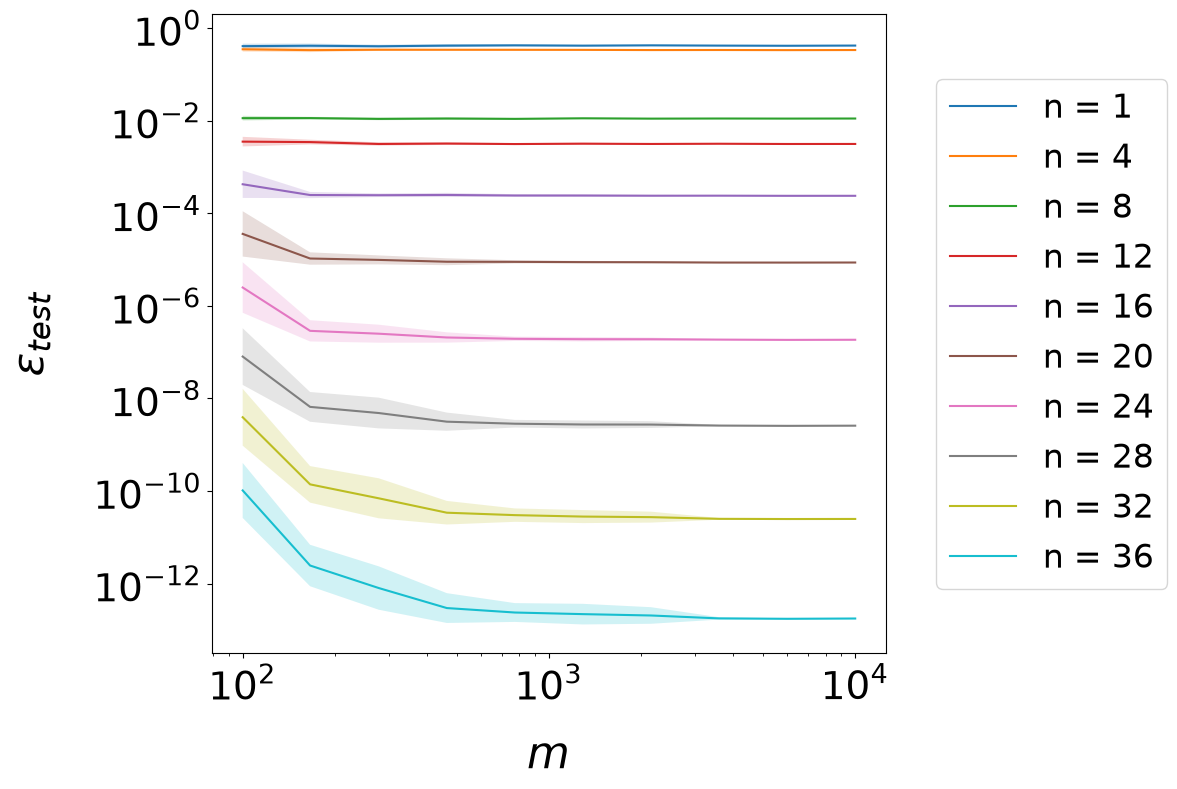

In [18]:

# Plot error over training set sizes
plt.figure(figsize=(12, 8))

results_mean = np.mean(MSE, axis=2)
results_lower = np.std(MSE, axis=2) / results_mean

for i in range(len(n_basis_values)):
    plt.loglog(
        sample_sizes,
        results_mean[i, :],
        label=f'n = {n_basis_values[i]}'
    )
    plt.fill_between(
        sample_sizes,
        results_mean[i, :] / (1 + results_lower[i, :]),
        results_mean[i, :] * (1 + results_lower[i, :]),
        alpha=0.2
    )

plt.xlabel(r'$m$', fontsize=32, labelpad=18)
plt.ylabel(r'$\epsilon_{test}$', fontsize=32, labelpad=28)

# Increase font size of axis tick labels
plt.tick_params(axis='both', which='major', labelsize=28)
plt.tick_params(axis='both', which='minor', labelsize=28)

plt.legend(
    fontsize=24,
    loc='center left',
    bbox_to_anchor=(1.05, 0.5),
    ncol=1
)

plt.tight_layout()
plt.savefig("errorvsparams.pdf")
plt.show()
